In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
# Manipulatable Settings
num_simulations = 5000
num_agents = 150
num_p_arrays = 150 #divided by 4
margin = 0.15

In [12]:
def generate_values(margin):
    # Randomly generate a value in the range (0, 0.12)
    value1 = np.random.uniform(0, 0.12)

    # The remaining sum needed to complete the total to 1
    remaining_sum = 1 - value1

    # Randomly generate three values that sum to remaining_sum
    values = np.random.rand(3)
    values /= values.sum()  # Normalize to sum to 1
    values *= remaining_sum  # Scale to the remaining_sum

    # Combine the fixed value with the generated values
    all_values = np.concatenate(([value1], values))


    # Ensure the first and third are not similar, and the second and fourth are not similar
    while abs(all_values[0] - all_values[2]) < margin:# or abs(all_values[1] - all_values[3]) < 0.1: not needed
        value1 = np.random.uniform(0, 0.12)
        remaining_sum = 1 - value1
        values = np.random.rand(3)
        values /= values.sum()
        values *= remaining_sum
        all_values = np.concatenate(([value1], values))

    # Initialize a new 4x4 array
    result_array = np.zeros((4, 4))

    # Fill the new array with shifted versions of the original array
    for i in range(4):
        result_array[i] = np.roll(all_values, shift=i)

    return result_array

In [13]:
combined_p_arrays = np.zeros((0, 4))

for i in range(num_p_arrays):
    p_arrays_temp = generate_values(margin)
    combined_p_arrays = np.vstack((combined_p_arrays, p_arrays_temp))

#print(combined_p_arrays)

In [14]:
# Define the box dynamics
region_movements = {
    1: (0, -1),
    2: (-1, 0),
    3: (0, 1),
    4: (1, 0),
}

# Number of simulations per distribution
num_distributions = combined_p_arrays.shape[0]

# Arrays to store cumulative movements
cumulative_x_movement = np.zeros(num_simulations)
cumulative_y_movement = np.zeros(num_simulations)

# Perform simulations
for i in range(num_simulations):
    # Generate random region selections based on probabilities
    p = combined_p_arrays[i % num_distributions]
    agent_regions = np.random.choice(list(region_movements.keys()), size=num_agents, p=p) #100 s

    # Calculate net movements in x and y directions
    total_x_movement = sum(region_movements[region][0] for region in agent_regions)
    total_y_movement = sum(region_movements[region][1] for region in agent_regions)

    # Store cumulative movements
    cumulative_x_movement[i] = total_x_movement
    cumulative_y_movement[i] = total_y_movement

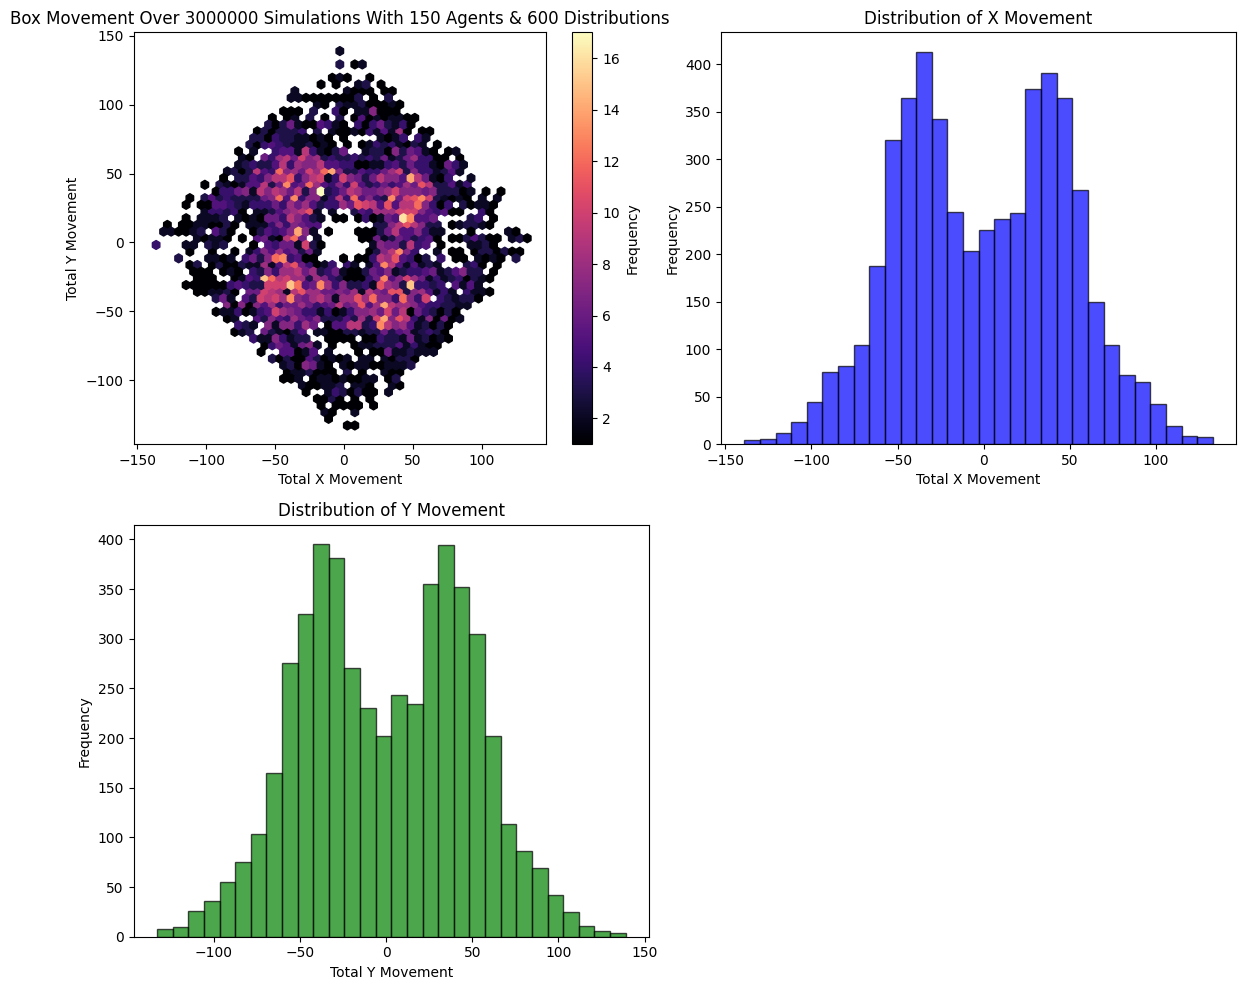

In [15]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot for hexbin of x vs y movement
hb = axs[0, 0].hexbin(cumulative_x_movement, cumulative_y_movement, gridsize=50, cmap='magma', mincnt=1)
cb = fig.colorbar(hb, ax=axs[0, 0])
cb.set_label('Frequency')
axs[0, 0].set_title(f'Box Movement Over {num_simulations * num_distributions} Simulations With {num_agents} Agents & {num_distributions} Distributions')
axs[0, 0].set_xlabel('Total X Movement')
axs[0, 0].set_ylabel('Total Y Movement')

# Plot for x movement histogram
axs[0, 1].hist(cumulative_x_movement, bins=30, color='blue', edgecolor='black', alpha=0.7)
axs[0, 1].set_title('Distribution of X Movement')
axs[0, 1].set_xlabel('Total X Movement')
axs[0, 1].set_ylabel('Frequency')

# Plot for y movement histogram
axs[1, 0].hist(cumulative_y_movement, bins=30, color='green', edgecolor='black', alpha=0.7)
axs[1, 0].set_title('Distribution of Y Movement')
axs[1, 0].set_xlabel('Total Y Movement')
axs[1, 0].set_ylabel('Frequency')

# Remove the empty subplot space
fig.delaxes(axs[1, 1])

plt.tight_layout()
plt.show()

In [16]:
def measure_uniformity(hist):
    # Calculate the variance of bin counts
    mean_count = np.mean(hist)
    std_dev = np.std(hist)

    # Compute the Coefficient of Variation (CV)
    if mean_count == 0:
        cv = np.inf  # Handle division by zero if mean_count is zero
    else:
        cv = std_dev / mean_count

    # Normalize the uniformity score to range [0, 1]
    # Inverting CV and scaling to [0, 1] range
    uniformity_score = 1 / (1 + cv)  # Smaller CV means higher uniformity
    return uniformity_score

In [17]:
def fitness_function(x, y, num_agents, total_bins):
    # Convert inputs to numpy arrays for convenience
    x = np.array(x)
    y = np.array(y)

    # Compute Manhattan distances from origin
    distances = np.abs(x) + np.abs(y)

    # Criteria 1: Few points near the origin
    # Points are considered near origin if their Manhattan distance is <= num_agents/5
    near_origin_count = np.sum(distances <= num_agents / 5)
    total_points = len(distances)

    # Fitness for avoiding origin
    fitness_origin_avoidance = 1 - (near_origin_count / total_points)

    # Criteria 2: Spread out the points
    # Compute the angle of each point from the origin
    angles = np.arctan2(y, x) * (180 / np.pi)  # Convert radians to degrees
    angles = (angles + 360) % 360  # Normalize angles to range [0, 360)

    # Define bin edges for *total_bins* bins, each representing 6 degrees
    bin_edges = np.linspace(0, 360, total_bins + 1)  # total_bins + 1 edges for total_bins bins

    # Calculate histogram of angles
    hist, _ = np.histogram(angles, bins=bin_edges)

    # Plot histogram
    plt.figure(figsize=(10, 6))
    plt.bar(bin_edges[:-1], hist, width=np.diff(bin_edges), edgecolor='black', alpha=0.7)
    plt.xlabel('Angle (Degrees)')
    plt.ylabel('Number of Points')
    plt.title('Histogram of Point Directions')
    plt.grid(True)
    plt.show()

    density = measure_uniformity(hist)

    print("fitness_origin_avoidance :" + str(fitness_origin_avoidance))
    print("density: " + str(density))

    return fitness_origin_avoidance, density

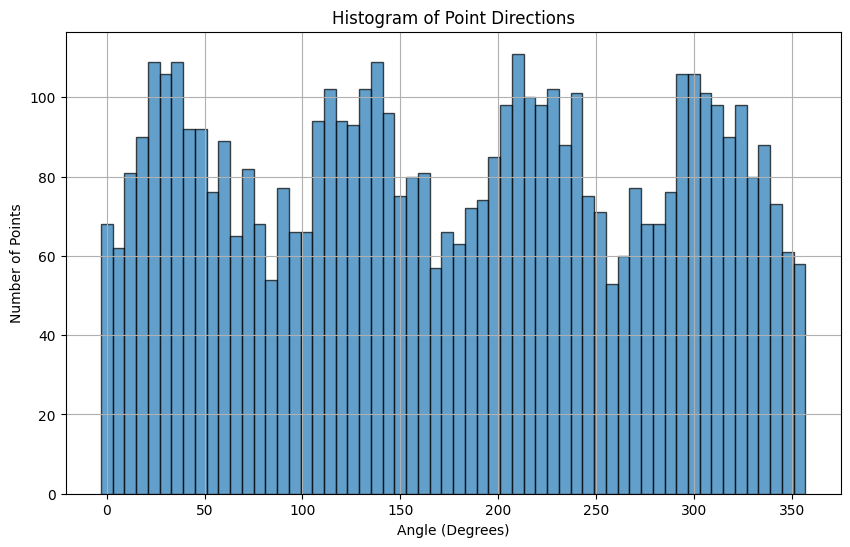

fitness_origin_avoidance :0.9838
density: 0.8364433471095245
(0.9838, 0.8364433471095245)


In [18]:
print(fitness_function(cumulative_x_movement, cumulative_y_movement, num_agents, 60))